# Beyond Pixel-Based Analysis

So far in this course, you may have been dissatisfied at the outputs of your satellite classifications. The *objects* we have been trying to map (vegetaion burn scars, forest, lakes, glaciers, etc.) are usually much larger than the pixel size of our satellite imagery. However, we have been classifying individual pixels based on the spectral properties of those pixels alone, rather than trying to include information about the context in wihch those pixels sit, or the wider object as a whole. This is known as *pixel-based image analysis*, and it's why our classifications often have a distinctive speckled 'salt-and-pepper' appearance, as we saw at the end of the previous notebook.

Here, we'll look to move from pixels towards objects, by using *image segmentation* to group pixels together before classifying them. We'll finish by briefly discussing how we might use deep learning approaches to take this further.

We'll be using `scikit-image`, which you'll need to install if you haven't already (e.g. `conda activate gsc` and then `conda install -c conda-forge scikit-image`). We'll also be using the files we saved in the previous notebook.

In [5]:
import numpy as np
import pandas as pd
import xarray as xr
import rioxarray as rxr
import geopandas as gpd
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from rasterio.features import shapes
from shapely.geometry import shape

from skimage.filters.rank import majority
from skimage.measure import label, regionprops_table
from skimage.morphology import remove_small_objects
from skimage.segmentation import slic, felzenszwalb, mark_boundaries

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

## Load data

Let's load our Landsat scene, the simplified land cover labels, and our pixel-based classification from the previous notebook. We'll also set up our class colours and plotting function again.

In [6]:
scene = rxr.open_rasterio("bristol_2021-07-21_landsat-8.tif", masked=True).squeeze()
scene["band"] = list(scene.attrs["long_name"])

labels = rxr.open_rasterio("bristol_2021_io-lulc-simplified.tif", masked=True).squeeze(drop=True)
prediction_pixel = rxr.open_rasterio("bristol_2021_rf-pixel-classification.tif", masked=True).squeeze(drop=True)

bands = list(scene["band"].values)
rgb = scene.sel(band=["red", "green", "blue"])

class_names = {1: "Water", 2: "Trees", 3: "Grass/crops", 4: "Urban"}
class_colours = ["#419bdf", "#397d49", "#e3c26b", "#c4281b"]


def plot_classes(da, ax, title=None):
    """Plot a classified DataArray with values 1-4 using our class colours."""
    da.plot.imshow(
        ax=ax, cmap=ListedColormap(class_colours),
        vmin=0.5, vmax=4.5, add_colorbar=False
        )
    handles = [Patch(color=c, label=class_names[i + 1]) for i, c in enumerate(class_colours)]
    ax.legend(handles=handles, loc="lower right", fontsize=8)
    ax.set_aspect("equal")
    ax.set_title(title)

## Neighbourhood Operations

<!-- ORIGINAL VERSION: ## Image Convolutions -->

So far, almost everything we've done to our imagery has been what GIS 'map algebra' calls a *local* operation: the value of each output pixel only depends on the input value(s) at that same pixel. Calculating NDVI, or classifying a pixel based on its spectral values, are good examples. To start including information about the *context* a pixel sits in, we can instead use *neighbourhood* (or *focal*) operations. Here, a small window (e.g. 3x3 pixels) is moved across the image, and the value of each output pixel is calculated from all of the input pixels within the window centred on it.

The most important family of neighbourhood operations are [convolutions](https://en.wikipedia.org/wiki/Kernel_(image_processing)). In a convolution, the window is a small grid of weights known as a *kernel*. At each pixel, we multiply every value within the window by the corresponding weight in the kernel, and add them all up. The result becomes the new value of the central pixel. We then slide the kernel along by one pixel and repeat, until we've covered the whole image.

```{figure} ../../img/image-convolution.png
:alt: Example of an image convolution.
:class: bh-primary
:width: 450px
:align: center
Example of applying a kernel (in this case, a 3x3 image sharpening kernel) to an image. Image source: [Gregory Gundersen](https://gregorygundersen.com/blog/2017/02/24/cnns/).
```

Because a convolution is just a weighted sum, the output depends entirely on the weights we choose. We can design a number of different kernels that result in different outputs that might be useful:

| Original | Gaussian Blur | Sharpen | Edge Detection |
| - | - | - | - |
| $\begin{bmatrix} 0 & 0 & 0 \\ 0 & 1 & 0 \\ 0 & 0 & 0 \end{bmatrix}$ | $\frac{1}{16} \begin{bmatrix} 1 & 2 & 1 \\ 2 & 4 & 2 \\ 1 & 2 & 1 \end{bmatrix}$ | $\begin{bmatrix} 0 & -1 & 0 \\ -1 & 5 & -1 \\ 0 & -1 & 0 \end{bmatrix}$ | $\begin{bmatrix} -1 & -1 & -1 \\ -1 & 8 & -1 \\ -1 & -1 & -1 \end{bmatrix}$ |
| ![Original image](https://upload.wikimedia.org/wikipedia/commons/5/50/Vd-Orig.png?utm_source=en.wikipedia.org&utm_campaign=parser&utm_content=thumbnail_unscaled) | ![Gaussian Blur](https://upload.wikimedia.org/wikipedia/commons/2/28/Vd-Blur1.png?utm_source=en.wikipedia.org&utm_campaign=parser&utm_content=thumbnail_unscaled) | ![Sharpen](https://upload.wikimedia.org/wikipedia/commons/4/4e/Vd-Sharp.png?utm_source=en.wikipedia.org&utm_campaign=parser&utm_content=thumbnail_unscaled) | ![Edge Detection](https://upload.wikimedia.org/wikipedia/commons/0/0b/Vd-Rige2.png?utm_source=en.wikipedia.org&utm_campaign=parser&utm_content=thumbnail_unscaled) |

Using convolutions we can, for instance, take a local average, [detect sharp linear features](https://en.wikipedia.org/wiki/Edge_detection), or calculate the rate of change across a surface. The latter is the basis of many [terrain attributes](https://xdem.readthedocs.io/en/stable/terrain.html): slope and aspect are calculated from a pair of convolutions that estimate how quickly elevation changes in the x and y directions, which are then combined.

However, not every neighbourhood operation is a convolution. We can apply any function we like to the pixels within the moving window, not just a weighted sum. For example:

 - A *majority* (or *mode*) filter replaces each pixel with the most common value in its window. Similarly, a *median* filter replaces each pixel with the median of the values in its window.
 - [Erosion and dilation](https://en.wikipedia.org/wiki/Erosion_(morphology)) of binary classifications take the local minimum and maximum.
 - Texture measures (such as those calculated from a 'grey-level co-occurrence matrix', available through `skimage.feature.graycomatrix()`) can describe how 'rough' or 'smooth' the area around each pixel is, and can be added as extra features to a classifier.

These are all still moving-window operations, but they can't be written down as a kernel of weights. It's worth keeping the distinction in mind, as convolutions will come back again when we discuss deep learning at the end of this notebook.

One common way we can use neighbourhood operations to our advantage is as a post-processing step: it is common to apply a 3x3 median or majority filter to an image to reduce the amount of speckle. 

For our pixel-based classified image we will use the majority, rather than the median? Our classes are *categorical*: the numbers 1-4 are just labels, and their order is arbitrary. Taking the median of labels can therefore give odd results. For instance, if a 3x3 window contains four 'Water' (1) pixels, one 'Trees' (2) pixel, and four 'Urban' (4) pixels, the median is 'Trees', even though it makes up only one ninth of the window! The majority filter doesn't care about the order of the classes, just how often each one appears. Median filters are instead a great choice for *continuous* data (such as reflectance values or elevation), where they're widely used to remove noise and 'spikes' whilst preserving sharp edges better than a mean (e.g. using `scipy.ndimage.median_filter()`).

Let's apply a majority filter to our pixel-based Random Forest classification from the previous notebook.

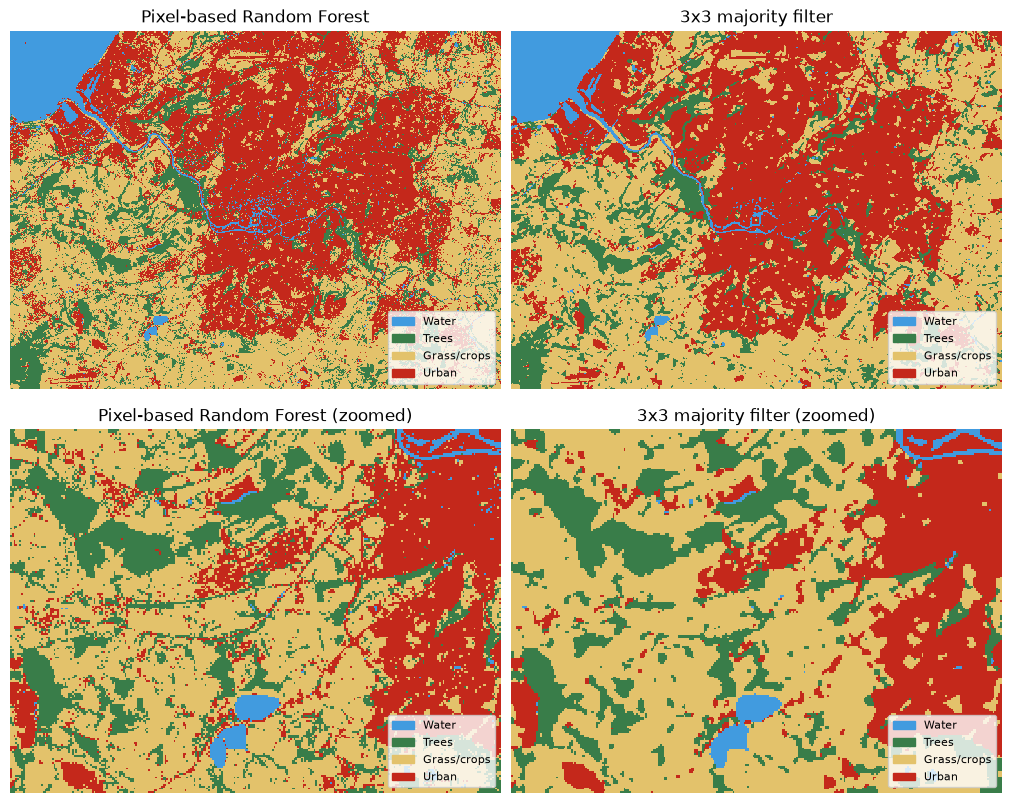

Pixel-based agreement with io-lulc: 0.805
Majority filtered agreement with io-lulc: 0.849


In [7]:
# `majority()` needs integer values, so we convert our classification (which
# is stored as floats) to unsigned 8-bit integers first. Note that it doesn't
# handle NaN values: our classification doesn't contain any, but if yours does
# you'll need to deal with them first (e.g. using the `mask` argument)
prediction_int = prediction_pixel.values.astype("uint8")

# Apply a 3x3 majority (mode) filter, using a 3x3 window of ones as the 'footprint'
prediction_mode = prediction_pixel.copy(
    data=majority(prediction_int, footprint=np.ones((3, 3), dtype="uint8"))
    )

# Zoom into the south-west of the city (we'll look at this area again later)
zoom = (slice(300, 500), slice(100, 370))

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 8), layout="constrained")

plot_classes(prediction_pixel, axes[0, 0], title="Pixel-based Random Forest")
plot_classes(prediction_mode, axes[0, 1], title="3x3 majority filter")
plot_classes(prediction_pixel[zoom], axes[1, 0], title="Pixel-based Random Forest (zoomed)")
plot_classes(prediction_mode[zoom], axes[1, 1], title="3x3 majority filter (zoomed)")

for ax in axes.flat:
    ax.set_axis_off()

plt.show()

for name, pred in [("Pixel-based", prediction_pixel), ("Majority filtered", prediction_mode)]:
    agreement = float((pred == labels).where(labels.notnull()).mean())
    print(f"{name} agreement with io-lulc: {agreement:.3f}")

# Calculate 3x3 median of our prediction pixels using skimage, plot the comparison of the original and smoothed predictions

The majority filter has removed much of the speckle, whilst keeping the overall pattern of land cover, and it has also improved agreement with the `io-lulc` labels. However, look closely at the zoomed-in panels: narrow linear features (such as roads and the river) have been broken up or removed entirely, because they are only one or two pixels wide and so are 'outvoted' by their neighbours. As with most post-processing, there is a trade-off between removing noise and removing real (but small) features.

## GEOBIA

Neighbourhood approaches still aren't really gathering information over what we might call an 'image object': a contiguous group of pixels that represent a meaningful _thing_ in the landscape (such as a lake, a field, or a forest). Working with image objects rather than individual pixels is known as (Geographic) Object-Based Image Analysis, or GEOBIA (or just OBIA).

### Image Segmentation (Clustering)

Image segmentation divides an image into regions (segments) of pixels. Unlike classification, segmentation doesn't tell us _what_ each region is: it just makes a best attempt to group pixels together based on their spectral values. The idea is that we can then use our own techniques to classify each segment as a whole, rather than each pixel individually.

`scikit-image` is the go-to Python library for general image processing. It contains tools for filtering, morphology, feature detection, and much more. It also contains some segmentation algorithms: the [`scikit-image` gallery](https://scikit-image.org/docs/stable/auto_examples/segmentation/plot_segmentations.html) shows a comparison of four popular approaches as applied to a (non-satellite) image:

![Comparison of segmentation approaches from the scikit-image gallery](../../img/skimage-segmentation.png)

Felzenszwalb's method and Quickshift both try to segment coherent regions of similar colours. They produce segments of very different shapes and sizes, which, in principle, identify coherent, meaningful, object-like segments. In practice (as you can see) they do a reasonable job but don't really identify fully coherent objects,. It can take a lot of manual playing around with function parameters to get sensible results. 

SLIC (Simple Linear Iterative Clustering) takes a slightly different philosophy. Its purpose isn't really to identify entire objects, but to group pixels into small, approximately evenly-sized clusters known as 'superpixels'. The most important target of superpixels is that their boundaries follow the edges in the image. This is 'over-segmentation': each real-world object is made up of several superpixels, but each superpixel should only contain one type of thing. Therefore, we can classify a superpixel as a whole, avoiding the speckle of pixel-based approaches.

Let's apply SLIC superpixel segmentation to our Bristol image. As in our previous notebook, there are a few practical quirks to be aware of when trying to feed satellite data into `scikit-image` (which is built around traditional image appraoches).

 - `scikit-image` expects images in the shape `(y, x, channel)`. `xarray` gives us `(band, y, x)`. We need to transpose our data, telling the function which axis contains bands (`channel_axis=-1`, i.e. the last axis).
 - Most `scikit-image` functions are designed for RGB or monochrome photographs, with values between 0 and 1 (or 0 and 255 for 8-bit imagery). Our reflectance values mostly fall between 0 and 0.3 - although some bands are much brighter than others. It's a good idea to rescale each band to between 0 and 1 first.
 - `scikit-image` functions don't recognise `NaN` values. Instead, SLIC has a `mask` argument: we can use the `NaN` vlaues as a base to tell it which pixels to ignore.

In [8]:
# Transpose from (band, y, x) to (y, x, band) and convert to a numpy array
img = scene.transpose("y", "x", "band").values

# Identify valid pixels (no NaN values in any band)
valid_mask = ~np.isnan(img).any(axis=-1)

# Rescale each band to 0-1, using the 2nd and 98th percentiles to avoid outliers
lower = np.nanpercentile(img, 2, axis=(0, 1))
upper = np.nanpercentile(img, 98, axis=(0, 1))
img_scaled = np.clip((img - lower) / (upper - lower), 0, 1)
img_scaled[~valid_mask] = 0

Now we can run the SLIC segmentation process. The two key arguments are `n_segments` (the approximate number of segments we want to split our image into) and `compactness` (higher values give more regular, square-ish segments, whilst lower values let segments follow the image more closely). Choosing values that are appropriate for your image involves a bit of trial and error: it's worth experimenting with them yourself! This might take a few seconds.

In [9]:
%%time

segments_slic = slic(
    img_scaled,
    n_segments=5000,
    compactness=0.1,
    channel_axis=-1,
    mask=valid_mask,
    start_label=1,
    )

print(f"Number of segments: {segments_slic.max()}")

Number of segments: 3267
CPU times: user 11.3 s, sys: 67.6 ms, total: 11.3 s
Wall time: 11.3 s


For comparison, let's also run Felzenszwalb's method. This has the advantage of being much quicker. Here, `scale` sets the size of segments (higher values mean larger segments), and `min_size` sets the minimum segment size (in pixels):

In [10]:
segments_fz = felzenszwalb(img_scaled, scale=500, sigma=0.5, min_size=30, channel_axis=-1)

print(f"Number of segments: {segments_fz.max() + 1}")

Number of segments: 981


The `mark_boundaries()` function is a useful tool for qualitative assessment: it draws the segment boundaries on top of an RGB image. Our segments are quite small, so it's hard to see much if we visualise the whole scene. Instead, we'll zoom into the south-west of the city, where the urban area meets fields and woodland.

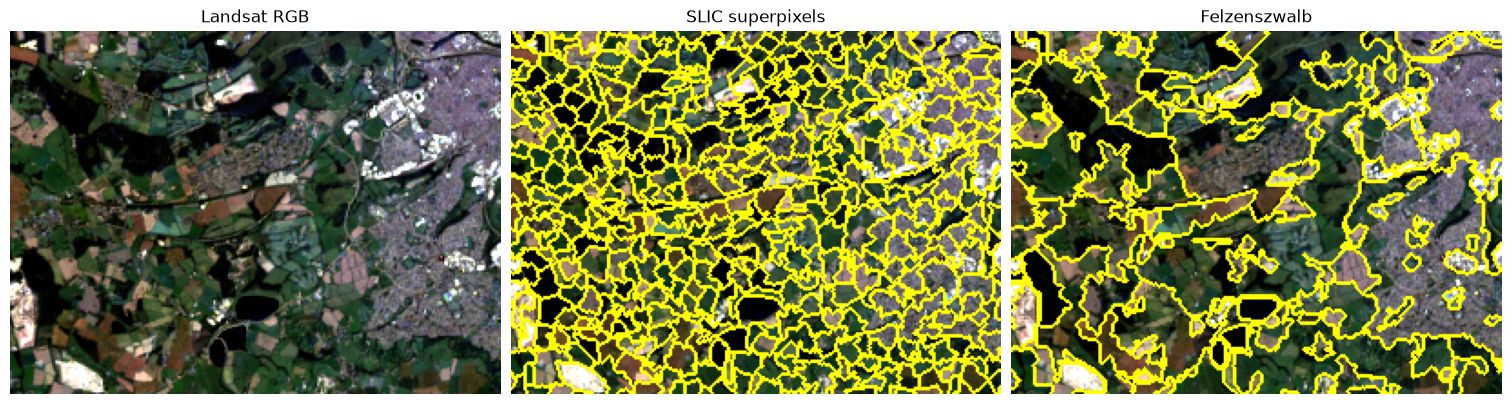

In [11]:
# Select a zoomed-in area using index slicing
zoom = (slice(300, 500), slice(100, 370))

# Our scaled image has bands in the order red, green, blue, nir08, swir16,
# so the first three bands make an RGB image
rgb_scaled = img_scaled[..., :3]

fig, axes = plt.subplots(ncols=3, figsize=(15, 4), layout="constrained")

axes[0].imshow(rgb_scaled[zoom])
axes[0].set_title("Landsat RGB")

axes[1].imshow(mark_boundaries(rgb_scaled[zoom], segments_slic[zoom], color=(1, 1, 0)))
axes[1].set_title("SLIC superpixels")

axes[2].imshow(mark_boundaries(rgb_scaled[zoom], segments_fz[zoom], color=(1, 1, 0)))
axes[2].set_title("Felzenszwalb")

for ax in axes:
    ax.set_axis_off()

plt.show()

The SLIC superpixels are all roughly the same size, but their boundaries follow the edges of land use types fairly well - you can track features such as roads and forst edges along the yellow lines. The Felzenszwalb segments vary much more in size, shape, and appearance. Some follow individual fields/woods closely, whereas others extent across large areas containing multiple different types of land cover. (this is particularly clear in the urban area on the right). Neither approach is 'correct', and both would need more tuning for a real application. However, they give us a useful initial set of segments to work with.

### Using segmentation with ML approaches

Now let's use our SLIC segments to classify the image. Rather than giving our Random Forest a training dataset where one row represents one pixel, we'll give it one  where one row represents one segment. 

We have to choose what these our training values will be. An obvious choice would be the average (mean or median) value of each band within a segment. However, one potential advantage of the segment approach is that we can include more information about each segment than just the average values. For instance, we could include the standard deviation of the band values within each segment: low values would inidicate a uniforms surface, like a field; whilst high values would indicate a varied segment, like a suburb. For segmentation approaches like Felzenszwalb that produce objects of varying shapes, we could also include information about the *shape* of each segment. This might quanitify features such as its area, or how elongated it is. (This is less useful for SLIC superpixels, which are designed to be roughly the same size and shape).

We can use the `scikit-image` [`regionprops_table()` function](https://scikit-image.org/docs/stable/api/skimage.measure.html#skimage.measure.regionprops) to calculate the values of regions within labelled segments. We pass our labelled segments (`segments_slic`), and our original (unscaled) image (`img`) as the `intensity_image`. We can select the `properties` of which we calculate - we will explicitly include the `mean` and `std` of the intensity image. This ultimately calculates the statistics of the pixel values within each segment, for each band:

In [12]:
seg_props = regionprops_table(
    segments_slic,
    intensity_image=img,
    properties=["label", "area", "intensity_mean", "intensity_std"],
    )

df_seg = pd.DataFrame(seg_props)

# Give the columns more helpful names (e.g. 'intensity_mean-0' becomes 'red_mean')
df_seg = df_seg.rename(columns={"label": "segment_id"})
for i, band in enumerate(bands):
    df_seg = df_seg.rename(columns={f"intensity_mean-{i}": f"{band}_mean", f"intensity_std-{i}": f"{band}_std"})

df_seg

,segment_id,area,red_mean,green_mean,blue_mean,nir08_mean,swir16_mean,red_std,green_std,blue_std,nir08_std,swir16_std
0,1,58.0,0.107093,0.089589,0.050033,0.117697,0.108649,0.005584,0.003956,0.002782,0.014364,0.024250
1,2,110.0,0.096313,0.083840,0.046773,0.061689,0.015263,0.002229,0.000820,0.000519,0.008832,0.012490
2,3,95.0,0.095911,0.083819,0.046523,0.057715,0.009873,0.002562,0.000967,0.000867,0.006476,0.001421
3,4,108.0,0.078858,0.079226,0.043606,0.033809,0.008232,0.003376,0.000681,0.000493,0.003664,0.000645
4,5,92.0,0.084851,0.080238,0.043528,0.040620,0.009028,0.004866,0.001191,0.000661,0.006343,0.002458
...,...,...,...,...,...,...,...,...,...,...,...,...
3262,3263,61.0,0.055037,0.065837,0.033867,0.331493,0.189649,0.012238,0.008358,0.006932,0.047554,0.024688
3263,3264,45.0,0.045686,0.064300,0.028793,0.448768,0.202561,0.004881,0.003050,0.003693,0.033883,0.010344
3264,3265,49.0,0.122431,0.110954,0.076670,0.230692,0.247607,0.014031,0.010994,0.010690,0.018932,0.026419
3265,3266,50.0,0.049231,0.059725,0.028585,0.299668,0.154493,0.008986,0.004483,0.004107,0.022634,0.011030


Next, we need to assign each segment a land use label from the `io-lulc` map. The most sensible way to this is to find the most common class within each segment (the mode). A convenient way of doing this is with `pd.crosstab()`, which counts how many pixels of each class fall within each segment. Then, using `.idxmax()`, we can pick the class with the highest count of values within the segment:

In [13]:
seg_flat = segments_slic.ravel()
labels_flat = labels.values.ravel()

# Only use pixels that are within a segment and have a label
ok = (seg_flat > 0) & ~np.isnan(labels_flat)

# Count the pixels of each class within each segment, and pick the most common
majority_class = pd.crosstab(seg_flat[ok], labels_flat[ok]).idxmax(axis=1)

df_seg["label"] = df_seg["segment_id"].map(majority_class)

df_seg["label"].map(class_names).value_counts()

label
Grass/crops    1614
Urban          1182
Trees           269
Water           202
Name: count, dtype: int64

Now we can train a Random Forest, in the same way we did in the previous notebook. We have only few thousand segments, rather than hundreds of thousands of pixels. As a result, we'll use all of them, holding back 30% for testing. Our classes are imbalanced, so I've set `class_weight="balanced"` to allow the training process to account for this.

Thinking back to the spatial autocorrelation problem from before: as our segments are larger and less tightly packed than individual pixels, so a random split suffers less from spatial autocorrelation. (it doesn't solve it completely, though, as neighbouring segments can still be very similar).

In [14]:
features = [f"{band}_mean" for band in bands] + [f"{band}_std" for band in bands]

df_seg = df_seg.dropna(subset=["label"])

X_train, X_test, y_train, y_test = train_test_split(
    df_seg[features], df_seg["label"], test_size=0.3, stratify=df_seg["label"], random_state=42
    )

model_seg = RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1)
model_seg.fit(X_train, y_train)

y_pred = model_seg.predict(X_test)

print(classification_report(y_test, y_pred, target_names=list(class_names.values())))

              precision    recall  f1-score   support

       Water       0.98      1.00      0.99        61
       Trees       0.72      0.88      0.79        81
 Grass/crops       0.94      0.89      0.92       484
       Urban       0.91      0.93      0.92       355

    accuracy                           0.91       981
   macro avg       0.89      0.93      0.91       981
weighted avg       0.92      0.91      0.91       981



Now we have to use the model to predict the class of every segment, mapping the predictions back onto the image. 

There's a neat little `numpy` trick for this. First, we create a 'lookup' array where the value at index `i` is the predicted class of segment `i`. Indexing this lookup array with our `segments_slic` array (where each pixel contains its segment ID) gives us our final image (where each pixel contains the segment's predicted class).

In [15]:
# Predict the class of every segment
df_seg["prediction"] = model_seg.predict(df_seg[features])

# Create a lookup array: lookup[segment_id] = predicted class (segment 0 = NaN)
lookup = np.full(segments_slic.max() + 1, np.nan)
lookup[df_seg["segment_id"]] = df_seg["prediction"]

# Index the lookup array with the segment image
prediction_obj = labels.copy(data=lookup[segments_slic])

We can compare this object-based prediction with the original `io-lulc` labels, as well as the pixel-based prediction from the previous notebook:

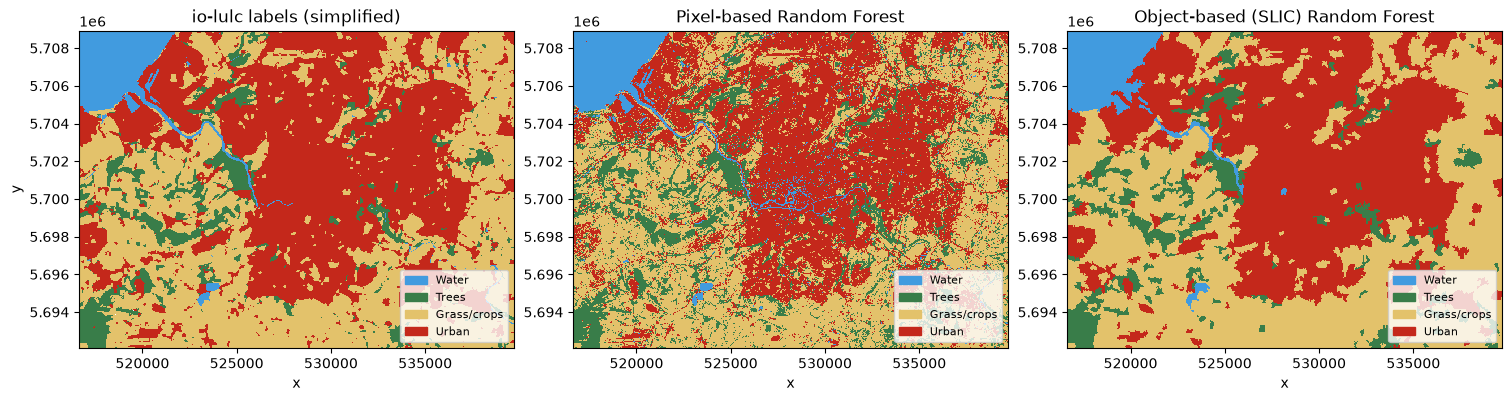

In [16]:
fig, axes = plt.subplots(ncols=3, figsize=(15, 4.5), layout="constrained")

plot_classes(labels, axes[0], title="io-lulc labels (simplified)")
plot_classes(prediction_pixel, axes[1], title="Pixel-based Random Forest")
plot_classes(prediction_obj, axes[2], title="Object-based (SLIC) Random Forest")

for ax in axes[1:]:
    ax.set_ylabel("")

plt.show()

And zooming in to the same area as before:

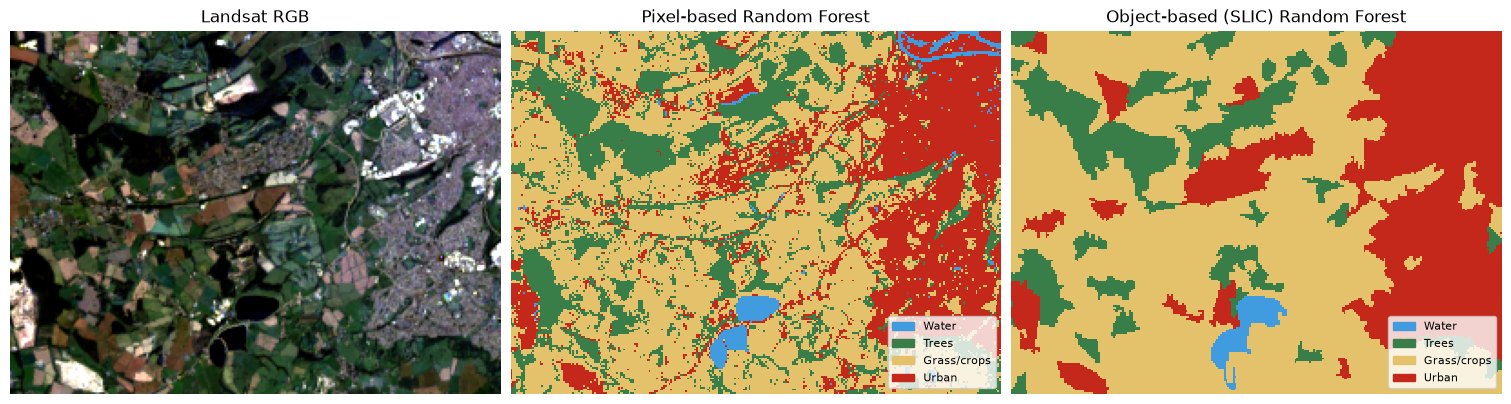

In [17]:
fig, axes = plt.subplots(ncols=3, figsize=(15, 4), layout="constrained")

axes[0].imshow(rgb_scaled[zoom])
axes[0].set_title("Landsat RGB")
axes[0].set_axis_off()

plot_classes(prediction_pixel[zoom], axes[1], title="Pixel-based Random Forest")
plot_classes(prediction_obj[zoom], axes[2], title="Object-based (SLIC) Random Forest")

for ax in axes[1:]:
    ax.set_axis_off()

plt.show()

The object-based classification is much 'cleaner', with far less salt-and-pepper speckle. The boundaries of the segments often more neatly follow the edges of the objects in the image. This is often much closer to what we'd draw if we were mapping the area by hand. 

However, you will also note weaknesses as well. Even if the pixel-based approach is noisier, it also captures finer-scale features such as roads that our segmentation approach did not delineate. This returns to the principle I outlined at the beginning of this document: object-based approaches are useful where the objects to be detected are much greater than the resolution of the imagery. In this case, roads are roughly the scale of the pixels, so pixel-based approaches are better at detecting them. In the larger image, we can also that the River Avon and Floating Harbour have disappeared in the objectbased approach.

We can check how well our two predictions agree with the `io-lulc` labels over the whole scene:

In [18]:
for name, pred in [("Pixel-based", prediction_pixel), ("Object-based", prediction_obj)]:
    agreement = float((pred == labels).where(labels.notnull()).mean())
    print(f"{name} agreement with io-lulc: {agreement:.3f}")

Pixel-based agreement with io-lulc: 0.805
Object-based agreement with io-lulc: 0.867


The object-based classification agrees more closely with the `io-lulc` labels - but remember that our training dataset is itself a deep learning model output, and so is 'smoother' than a typical pixel-based classification. As a result, part of the improvement is possible that our our object-based map now 'looks' more like the labels. 

There are some important trade-offs to bear in mind when using object-based approaches. Our result now depends heavily on our segmentation parameters: we can see this looking at how the lakes in the figure above don't perfectly track the true lake edges. If segments are too large, they will contain more than one land cover type. If they are too small or small or narrow, features will be lost entirely.  Choosing the 'right' segmentation scale is often a matter of manual trial and error for each application - which sort of removes the point of an automated machine learning approach!

## Deep learning approaches

There's no code in this section. Instead, I want to give you a brief overview of where satellite image classification goes next: deep learning.

Approaches so far have all relied on us deciding what information the model gets to see. For instance, which spectral bands, any indices, the mean and standard deviation of segments, etc. Deep learning models accept the raw inputs, with the goal of learning their own features - even ones we wouldn't have anticipated. This makes them extremely powerful for image analysis, and they now dominate much of the cutting-edge Earth observation literature. 

It's easy to get excited by deep learning: it is wrapped up within all the other AI excitement that has come to dominate our current news cycles, economy, and society. However, it's worth saying that isn't always the right answer. Deep learning models need a lot (a huge amount relative to what we have seen so for) of labelled training data, as well as significant computing power (preferably GPU rather than CPU). It can be difficult to interpret why made the decisions they did, which can limit process understanding. For many problems, a well-designed traditional approach can be more than sufficient, and much easier to explain in your methods section.

### CNNs: the deep learning workhorse for Earth observation

Convolutional Neural Networks (CNNs) have been the dominant Earth observation deep learning approach for much of the last decade. 

At the beginning of this notebook, we discussed convolution operations, where a small kernel is passed over an image to calculate things like local averages or edges. A CNN contains many layers of these convolutions (hence 'deep learning'). However, rather than us choosing how each kernel is designed (and hence how it achieves our goal), in a CNN approach we merely prescribe the sizes of kernel and the structure of the network. Through the training process, the network learns what values (weights) the kernels should have in order to produce outputs that approximate its training dataset. Early layers tend to detect simpler features (edges, colours), whilst deeper layers resolve more complex patterns (e.g. land use boundaries, building shapes, river networks).

For classifying satellite imagery, the most popular CNN architecture is probably the U-Net. It was originally designed for biomedical images, and is named after it's shape: it a 'U'-shaped network. The first half (the 'encoder') progressively shrinks an image down to learn what is in it. The second half (the 'decoder') blows it back up to the original size to work out where things are. Through this, a class type can be produced for every pixel. Specific encoder designs for image classification network often have their own names (such as a ResNet or EfficientNet). 

```{figure} ../../img/u-net-architecture.png
:alt: Structure of a U-Net
:class: bh-primary
:width: 750px
:align: center
Structure of a U-Net, from the original U-Net paper by [Ronneberger et al.](https://doi.org/10.1007/978-3-319-24574-4_28). Starting with a 572x572x1 image (i.e. single-band greyscale), progressive image convolutions in the encoder transform the image to a 32x32 image with 1024 'bands' at the bottom of the U-Net, before the  decoder 'localises' this understanding again. 
```

If you start designing and applying deep learning approaches for Earth observation, there are (as always) a few practical issues that make satellite imagery unique and problematic compared to 'normal' computer vision workflows designed for traditional iamgery:

 - As we've seen, satellite images are very large, on the order of thousands of pixels. For memory purposes, they usually need to be split into smaller tiles (often called 'chips' or 'patches', e.g. 256 x 256 pixels) for training and prediction, and then stitched back together into a single image afterwards..
 - Images have three channels (red, green, blue), whilst satellites can have many more bands. Many pre-trained networks expect three-band photographs, so they cannot be directly applied or retrained onto satellite images.
 - Deep learning workflows do not preserve geospatial metadata. You need to preserve georeferencing and re-apply it to the final product.
 - Spatial autocorrelation is still a problem! Training and testing chips should be spatially separated to allow for independence.

### New approaches

#### Vision Transformers

In the last few years, a new family of models called vision transformers (ViTs) has become popular. They are based on the same 'transformer' architectures that are used to create large language models like ChatGPT. They work by splitting an image into small patches, with the aim of 'learning' how every individual patch relates to every other patch. This is designed to capture relationships across a whole image, rather than just within the local neighbourhood of a convolution.

One well-known example that is (i) relevant for this notebook; and (ii) you might already have heard of, is Meta's [Segment Anything Model (SAM)](https://github.com/facebookresearch/sam2). SAM was trained to segment almost anything in an image, often without any additional training. You can prompt it with a single point or a bounding box, or it can automatically segment everything in an image. An important point is that the original SAM models are 'class-agnostic': they tell you where, but not what, the objects. As a result, you still need a classification step afterwards (this is less true for SAM 3, which can be prompted by text to classify specific objects). SAM was trained on everyday photographs, so it works less well on medium-resolution satellite imagery where objects are only a few pixels across. If you want to try SAM on your own satellite data, the [`segment-geospatial`](https://samgeo.gishub.org/) package can handle georeferenced imagery in Python, and the [Geo-SAM](https://github.com/coolzhao/Geo-SAM) plugin allows you to use it within QGIS. However, installation and configuration is more difficult than for a traditional Python package, as you will need to succesfully set up the back-end deep learning package (PyTorch - see below).

#### Foundation Models

SAM is an example of a 'foundation model'. These are incredibly large model trained on a huge amount of data, often by large teams or organisations (this is not going to be a dissertation project...). The idea is that can then be adapted by smaller teams to lots of different individual tasks, as they have already been 'exposed' to the specific ideas in their original training and just need tuning. 

As discussed with SAM above, one problem is that foundation models trained on traditional phootgraphs don't necessarily translate well immediately understanding satellite images (I have often discovered whilst giving outreach talks that the same is true for people!). However, a growing number of geospatial foundation models are now trained specifically on satellite imagery. Usually this involes self-supervised learning on huge unlabelled archives (in plain language: labels are not applied during pre-training). They can then be 'fine-tunde' for your specific task using a relatively small labelled dataset. Examples include NASA and IBM's [Prithvi](https://huggingface.co/ibm-nasa-geospatial), [Clay](https://madewithclay.org/), and ESA and IBM's [TerraMind](https://huggingface.co/ibm-esa-geospatial). The [TerraTorch](https://github.com/IBM/terratorch) package provides tools for fine-tuning many of these models.

If this sounds out-of-reach for the scale of projects you might be able to achive to date, then there is another approach. As introduced in the previous notebook, you can take advantage of Google's AlphaEarth Foundations model, which produced the Satellite Embedding dataset mentioned in the previous notebook. Rather than fine-tuning and applying the model yourself, you can simply download the embeddings it produces and use them as features in a simple classifier, like a Random Forest. This brings some of the power of deep learning within reach of the techniques you've learnt in this course.

### Python, Earth Observation, and Deep Learning

Good news: if you're combining Earth Observation and Deep Learning, Python is the de-facto environment in which you will be operating. A full introduction is far beyond the scope of this course, but consider this a brief list of pointers towards the practical tools that you will have to learn to use if you want to develop this skillset.

 - [PyTorch](https://pytorch.org/) is the most widely used deep learning library in research. The official ['Learn the Basics'](https://pytorch.org/tutorials/beginner/basics/intro.html) tutorials are a good (non-geospatial-specific) starting point.
   - [TensorFlow](https://www.tensorflow.org/) is another common interface you might encounter in the literature, although this increasingly outcompeted by PyTorch. It also has a [very useful and user-friendly set of tutorials](https://www.tensorflow.org/tutorials).
 - [TorchGeo](https://torchgeo.readthedocs.io/) is a PyTorch library specifically designed to help you integate geospatial data with PyTorch workflows. It handles many of the practical issues listed above (georeferencing, multispectral data, tiling) and also can provide access to benchmark datasets and pre-trained models for satellite imagery. It also is [well-documented](https://docs.torchgeo.org/en/stable/index.html) with [useful tutorials](https://docs.torchgeo.org/en/stable/tutorials/index.html) that show how it integrates with PyTorch and geospatial data.
 - The [`segmentation-models-pytorch`](https://github.com/qubvel-org/segmentation_models.pytorch) package makes it easy to build U-Nets (and other architectures) with different backbones for the purposes of segmenting satellite imagery within PyTorch.
 - Benchmark datasets, such as [EuroSAT](https://github.com/phelber/EuroSAT) (scene classification of Sentinel-2 image chips), are a good way to practise training deep learning satasets without having to create your own labelled training datasets. Many other examples are already available through TorchGeo.
 - Robin Cole's [satellite-image-deep-learning](https://github.com/satellite-image-deep-learning) GitHub repository is a very comprehensive - and even slightly overwhelming! - list of techniques, examples, datasets, and papers. You can also subscribe to a newsletter to keep on top of new ideas.

## Summary

In this notebook, we've looked at how we might build more towards more advanced methods of classifying satellite imagery that goes beyond pixel-based approaches. Image segmentation (with the specific example of SLIC superpixels) groups similar pixels together, meaning we can classify local groups rather than individual pixels. This reduces the visisble "speckle" in classified imagery, and can allow us to use extra information about each segment. We've also touched upon modern deep learning approaches (CNNs, vision transformers, and foundation models), how they learn spatial patterns directly from imagery, and the route you might end up going down to learn more.

Next term, GEOGM0053 will give you a much more substantial methodological background to machine learning.